In [1]:
import os
import sys
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models.segmentation import deeplabv3_resnet50
import onnxruntime as ort
from PIL import Image
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
%matplotlib inline

In [2]:
# --- 1. CONFIGURATION ---
os.environ['TORCH_HOME'] = '/tmp/no_internet'
BASE_DIR = os.getcwd()

MODEL_FILENAME = "yolop-640-640.onnx"
PATH_MODEL_TO_TEST = os.path.join(BASE_DIR, "weights", MODEL_FILENAME)

PATH_IMAGES_VAL = os.path.join(BASE_DIR, "dataset", "images", "val")
PATH_LABELS_VAL = os.path.join(BASE_DIR, "dataset", "da_seg_annotations", "val")
PATH_RESULT_VIZ = os.path.join(BASE_DIR, "pictures")

NUM_CLASSES = 2
BATCH_SIZE = 1 

REF_IMAGE_NAME = "7dd9ef45-f197db95.jpg"
IMAGE_SIZE = (640, 640)


BDD_CLASSES = ["Background", "Road"]

In [3]:
class ConfusionMatrix:
    def __init__(self, num_classes):
        self.num_classes = num_classes
        self.mat = None

    def update(self, a, b):
        n = self.num_classes
        if self.mat is None:
            self.mat = torch.zeros((n, n), dtype=torch.int64, device=a.device)
        
        k = (a >= 0) & (a < n)
        inds = n * a[k].to(torch.int64) + b[k]
        self.mat += torch.bincount(inds, minlength=n**2).reshape(n, n)

    def compute(self):
        h = self.mat.float()
        acc_global = torch.diag(h).sum() / h.sum()
        acc_cls = torch.diag(h) / h.sum(1)
        iu = torch.diag(h) / (h.sum(1) + h.sum(0) - torch.diag(h))
        return acc_global.item() * 100, iu.mean().item() * 100, iu


In [4]:
class LocalBDDValDataset(Dataset):
    def __init__(self, img_dir, mask_dir, transform=None):
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        self.transform = transform
        
        if not os.path.exists(img_dir):
            print(f"ATTENTION: Dossier VAL introuvable : {img_dir}")
            print("Si tu n'as pas de dossier 'val', change le chemin vers 'train' pour tester.")
            sys.exit(1)

        self.images = [f for f in os.listdir(img_dir) if f.endswith('.jpg')]
        
        self.images = self.images[:200]

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_name = self.images[idx]
        mask_name = img_name.replace(".jpg", ".png")
        
        img_path = os.path.join(self.img_dir, img_name)
        mask_path = os.path.join(self.mask_dir, mask_name)

        # Vérification de l'existence de l'image
        if not os.path.exists(img_path):
            raise FileNotFoundError(f"Image introuvable : {img_path}")
        
        image = Image.open(img_path).convert("RGB")
        
        if os.path.exists(mask_path):
            mask = Image.open(mask_path).convert("L")
        else:
            mask = Image.new('L', image.size, 0)

        image = image.resize(IMAGE_SIZE, Image.BILINEAR)
        mask = mask.resize(IMAGE_SIZE, Image.NEAREST)

        if self.transform:
            image = self.transform(image)
            
        return image, torch.as_tensor(np.array(mask), dtype=torch.int64), img_name
                    

In [5]:

def save_comparison(image_tensor, pred_mask, true_mask, filename):

    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    img = image_tensor.cpu() * std + mean
    img = img.permute(1, 2, 0).numpy()
    img = np.clip(img, 0, 1)

    plt.figure(figsize=(15, 5))
    
    plt.subplot(1, 3, 1)
    plt.imshow(img)
    plt.title("Image Originale")
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(pred_mask.cpu().numpy(), cmap='jet', vmin=0, vmax=18)
    plt.title("Prédiction")
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(true_mask.cpu().numpy(), cmap='jet', vmin=0, vmax=18)
    plt.title("Vérité Terrain")
    plt.axis('off')

    plt.savefig(os.path.join(PATH_RESULT_VIZ, filename))
    plt.close()

In [6]:
# %%
def visualize_specific_image(image_name):
    """
    Cherche une image spécifique (Train ou Val), lance ONNX et affiche le rapport.
    """
    print(f"🔎 Recherche de l'image : {image_name}...")

    # 1. Recherche du fichier dans VAL puis TRAIN
    possibilities = [
        ("val", os.path.join(BASE_DIR, "dataset", "images", "val"), os.path.join(BASE_DIR, "dataset", "da_seg_annotations", "val")),
        ("train", os.path.join(BASE_DIR, "dataset", "images", "train"), os.path.join(BASE_DIR, "dataset", "da_seg_annotations", "train"))
    ]

    found = False
    img_path, mask_path = "", ""
    
    for split_name, img_dir, mask_dir in possibilities:
        p_img = os.path.join(img_dir, image_name)
        if os.path.exists(p_img):
            print(f"Trouvée dans le dossier : {split_name.upper()}")
            img_path = p_img
            # Le masque a le même nom mais en .png
            mask_path = os.path.join(mask_dir, image_name.replace(".jpg", ".png"))
            found = True
            break
    
    if not found:
        print(f"ERREUR : L'image {image_name} est introuvable dans 'val' ou 'train'.")
        return

    # 2. Chargement et Préprocessing
    image = Image.open(img_path).convert("RGB")
    
    # Gestion du masque (création d'un vide si absent)
    if os.path.exists(mask_path):
        mask = Image.open(mask_path).convert("L")
    else:
        print("Masque introuvable, génération d'un masque vide.")
        mask = Image.new('L', image.size, 0)

    # Redimensionnement initial (comme dans le dataset)
    image_pil = image.resize(IMAGE_SIZE, Image.BILINEAR)
    mask_pil = mask.resize(IMAGE_SIZE, Image.NEAREST)

    # Transformation en Tenseur
    transform_fn = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    
    img_tensor = transform_fn(image_pil).unsqueeze(0).to(device) 
    mask_np = np.array(mask_pil)

    ort_inputs = {session.get_inputs()[0].name: img_tensor.cpu().numpy()}
    ort_outs = session.run(None, ort_inputs)
    
    output = torch.from_numpy(ort_outs[1]).to(device)
    pred_tensor = output.argmax(1).squeeze(0).cpu()
    mask_tensor = torch.as_tensor(mask_np, dtype=torch.int64)

    mask_tensor[mask_tensor > 0] = 1 

    plt.figure(figsize=(18, 6))

    plt.subplot(1, 3, 1)
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img_visu = img_tensor.squeeze(0).permute(1, 2, 0).cpu().numpy() * std + mean
    plt.imshow(np.clip(img_visu, 0, 1))
    plt.title(f"Image : {image_name}")
    plt.axis('off')

    plt.subplot(1, 3, 2)
    im_pred = plt.imshow(pred_tensor.numpy(), cmap='jet', vmin=0, vmax=1)
    plt.title("Prédiction ONNX")
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(mask_tensor.numpy(), cmap='jet', vmin=0, vmax=1)
    plt.title("Vérité Terrain (Corrigée)")
    plt.axis('off')

    patches = [
        mpatches.Patch(color=im_pred.cmap(im_pred.norm(0)), label="Fond"),
        mpatches.Patch(color=im_pred.cmap(im_pred.norm(1)), label="Route")
    ]
    plt.legend(handles=patches, bbox_to_anchor=(1.05, 1), loc='upper left')

    save_file = os.path.join(PATH_RESULT_VIZ, f"TARGET_{image_name}.png")
    plt.savefig(save_file, bbox_inches='tight')
    print(f"Image sauvegardée : {os.path.abspath(save_file)}")
    plt.show()




Test sur : cuda
Chargement du modèle ONNX : yolop-640-640.onnx
Évaluation sur 200 images de validation...
Calcul des métriques...


  0%|                                          | 0/200 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/cuda/__init__.py:234: UserWarning: 
NVIDIA GeForce RTX 5060 Ti with CUDA capability sm_120 is not compatible with the current PyTorch installation.
The current PyTorch install supports CUDA capabilities sm_52 sm_60 sm_61 sm_70 sm_72 sm_75 sm_80 sm_86 sm_87 sm_90 compute_90.
If you want to use the NVIDIA GeForce RTX 5060 Ti GPU with PyTorch, please check the instructions at https://pytorch.org/get-started/locally/

  warnings.warn(
100%|████████████████████████████████| 200/200 [02:54<00:00,  1.14it/s]



 RÉSULTATS DU MODÈLE : yolop-640-640.onnx
 Global Pixel Accuracy : 95.41%
 Mean IoU (mIoU)       : 86.05%
----------------------------------------
 Détail par classe :
  - Background      : 94.55%
  - Road            : 77.55%
🔎 Recherche de l'image : 7dd9ef45-f197db95.jpg...
Trouvée dans le dossier : TRAIN
Image sauvegardée : /workspace/pictures/TARGET_7dd9ef45-f197db95.jpg.png


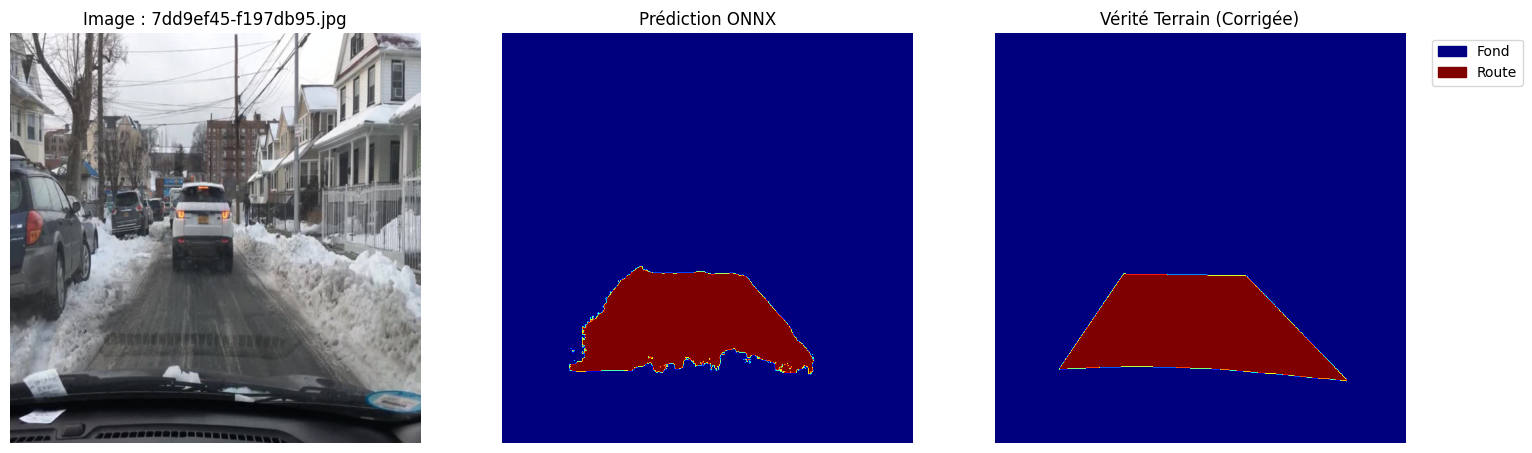

In [7]:
if __name__ == "__main__":
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Test sur : {device}")
    
    os.makedirs(PATH_RESULT_VIZ, exist_ok=True)

    print(f"Chargement du modèle ONNX : {MODEL_FILENAME}")
    if not os.path.exists(PATH_MODEL_TO_TEST):
        print(f"ERREUR : Fichier introuvable {PATH_MODEL_TO_TEST}")
        sys.exit(1)

    providers = ['CUDAExecutionProvider', 'CPUExecutionProvider'] if torch.cuda.is_available() else ['CPUExecutionProvider']
    session = ort.InferenceSession(PATH_MODEL_TO_TEST, providers=providers)
    input_name = session.get_inputs()[0].name

    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    dataset = LocalBDDValDataset(PATH_IMAGES_VAL, PATH_LABELS_VAL, transform=transform)
    dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False)
    print(f"Évaluation sur {len(dataset)} images de validation...")

    conf_mat = ConfusionMatrix(NUM_CLASSES)
    
    print("Calcul des métriques...")
    with torch.no_grad():
        for i, (images, masks, names) in enumerate(tqdm(dataloader)):
            images = images.to(device)
            masks = masks.to(device)

            ort_inputs = {input_name: images.cpu().numpy()}

            ort_outs = session.run(None, ort_inputs)

            output = torch.from_numpy(ort_outs[1]).to(device)
            preds = output.argmax(1)

            if masks.dim() == 4:
                masks = masks[:, :, :, 0]

            masks[masks > 0] = 1


            masks_resized = torch.nn.functional.interpolate(
                masks.unsqueeze(1).float(), 
                size=(preds.shape[1], preds.shape[2]), 
                mode='nearest'
            ).squeeze(1).long()

            # 4. Mise à jour UNIQUE de la matrice de confusion
            conf_mat.update(masks_resized.flatten(), preds.flatten())

            # 6. Sauvegarde des premières comparaisons
            if i == 0:
                for j in range(len(images)):
                    save_comparison(images[j], preds[j], masks_resized[j], f"result_{names[j]}.png")

    # 7. Affichage des scores finaux
    acc_global, miou, iou_per_class = conf_mat.compute()
    
    print("\n" + "="*40)
    print(f" RÉSULTATS DU MODÈLE : {MODEL_FILENAME}")
    print("="*40)
    print(f" Global Pixel Accuracy : {acc_global:.2f}%")
    print(f" Mean IoU (mIoU)       : {miou:.2f}%")
    print("-" * 40)
    print(" Détail par classe :")
    
    for idx, score in enumerate(iou_per_class):
        name = BDD_CLASSES[idx] if idx < len(BDD_CLASSES) else f"Class {idx}"
        print(f"  - {name:<15} : {score.item()*100:.2f}%")
        
    print("="*40)
    
    target_img = "7dd9ef45-f197db95.jpg"
    visualize_specific_image(target_img)
